## 1. TÌM HIỂU DỮ LIỆU

In [25]:
#Xem dữ liệu
import warnings, re
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_extraction.text import CountVectorizer

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 200)
train_df = pd.read_csv("train.csv")
train_df.head()

,asthma,smoking,COPD,season,hay_fever,pneu,dysp,cough,pain,fever,nasal,text,advanced_text
0,no,no,no,winter,no,0,no,no,no,none,no,"**History**\r\nPatient reports intermittent abdominal discomfort, described as a dull, achy sensation with episodes occurring post large meals. Symptoms have been present for the last two weeks. N...","**History**\r\nPt reports intermittent abd discomfort since 2 wks, described as dull, achy, worse post large meals. No n/v/d or change in bowel habits. Balanced diet, recent ↑ fatty foods. No GI h..."
1,no,yes,no,summer,no,1,yes,yes,no,high,yes,"**History**\r\nThe patient presents with a chief complaint of severe dyspnea, which has been progressively worsening over the last three days. They report a mild cough but deny any respiratory pai...","**History**\r\nPt presents w/ c/o severe dyspnea worsening over 3 days. Reports mild cough, denies resp pain. Nasal congestion and discharge x1 week. High fever x24hrs. Smoker. No recent travel or..."
2,no,no,no,summer,no,0,no,no,no,none,no,"**History** \r\nThe patient is concerned with intermittent gastrointestinal discomfort that seems to worsen with certain types of food, primarily spicy and greasy meals. The discomfort is describ...","**History** \r\nPt reports intermittent GI discomfort, particularly bloating/fullness, worsening with spicy/greasy foods. No N/V, changes in bowel habits. Denies fever, dyspnea, CP, sneezing, blo..."
3,no,no,no,summer,no,0,no,no,no,none,no,"**History**\r\nPatient describes periodic abdominal bloating and discomfort, particularly after meals, for the past month. The discomfort is diffuse and unaccompanied by significant pain, constipa...","**History**\r\nPt reports periodic abd bloating/discomfort after meals x 1 month. Discomfort is diffuse, no sig pain, constipation, diarrhea or blood in stools. No changes in appetite or wt. Incre..."
4,no,no,no,summer,no,0,yes,no,no,low,no,"**History** \r\nThe patient presents with complaints of dyspnea over the past 3 weeks, which has progressively worsened. Initially, dyspnea occurred during exertion, but more recently, it has bee...","**History** \r\nPt presents with 3-week hx of worsening dyspnea. Initially exertional, now present at rest. Denies cough, CP, wheezing, or recent URIs. No exposure to resp irritants or recent tra..."


In [26]:
#Xem chi tiết dữ liệu và bộ nhớ sử dụng
print(f"Số hồ sơ (dòng): {train_df.shape[0]:,} | Số cột: {train_df.shape[1]}")
print(f"Bộ nhớ sử dụng: {train_df.memory_usage(deep=True).sum()/1e6:.1f} MB\n")
train_df.info()

Số hồ sơ (dòng): 8,000 | Số cột: 13
Bộ nhớ sử dụng: 18.2 MB

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   asthma         8000 non-null   str  
 1   smoking        8000 non-null   str  
 2   COPD           8000 non-null   str  
 3   season         8000 non-null   str  
 4   hay_fever      8000 non-null   str  
 5   pneu           8000 non-null   int64
 6   dysp           8000 non-null   str  
 7   cough          8000 non-null   str  
 8   pain           8000 non-null   str  
 9   fever          8000 non-null   str  
 10  nasal          8000 non-null   str  
 11  text           8000 non-null   str  
 12  advanced_text  8000 non-null   str  
dtypes: int64(1), str(12)
memory usage: 812.6 KB


In [27]:
# Phân nhóm cột theo vai trò (bám theo mô tả bài toán trong đề cương)
TARGETS   = ["pneu"]
EXTERNAL  = ["season"]
HISTORY   = ["asthma", "hay_fever", "COPD", "smoking"]
SYMPTOMS  = ["dysp", "cough", "pain", "fever", "nasal"]    
TEXT_COLS = ["text", "advanced_text"]
TABULAR_FEATS = EXTERNAL + HISTORY + SYMPTOMS 

roles = pd.DataFrame({
    "cột": TARGETS + EXTERNAL + HISTORY + SYMPTOMS + TEXT_COLS,
    "vai trò": ["target"] + ["ngoại cảnh"] + ["bệnh nền"]*4 + ["triệu chứng"]*5 + ["văn bản"]*2,
})
roles["kiểu"] = roles["cột"].map(train_df.dtypes.astype(str))
roles["số giá trị khác nhau"] = roles["cột"].map(train_df.nunique())
roles

,cột,vai trò,kiểu,số giá trị khác nhau
0,pneu,target,int64,2
1,season,ngoại cảnh,str,2
2,asthma,bệnh nền,str,2
3,hay_fever,bệnh nền,str,2
4,COPD,bệnh nền,str,2
5,smoking,bệnh nền,str,2
6,dysp,triệu chứng,str,2
7,cough,triệu chứng,str,2
8,pain,triệu chứng,str,2
9,fever,triệu chứng,str,3


In [28]:
# Kiểm tra dữ liệu thiếu 
miss = train_df.isna().sum().to_frame("missing")
miss["%"] = (miss["missing"] / len(train_df) * 100).round(2)
print("Tổng số ô thiếu:", int(miss["missing"].sum()))
miss[miss["missing"] > 0] if miss["missing"].sum() else print("-> Không có giá trị thiếu.")

Tổng số ô thiếu: 0
-> Không có giá trị thiếu.


In [29]:
# Kiểm tra giá trị rỗng / khoảng trắng trong cột văn bản & giá trị lạ ở cột phân loại
for c in TEXT_COLS:
    print(f"{c}: rỗng = {(train_df[c].str.strip() == '').sum()}")

print()
for c in TABULAR_FEATS[:-1] + TARGETS:
    print(f"{c:12s} -> {sorted(train_df[c].unique().tolist())}")


text: rỗng = 0
advanced_text: rỗng = 0

season       -> ['summer', 'winter']
asthma       -> ['no', 'yes']
hay_fever    -> ['no', 'yes']
COPD         -> ['no', 'yes']
smoking      -> ['no', 'yes']
dysp         -> ['no', 'yes']
cough        -> ['no', 'yes']
pain         -> ['no', 'yes']
fever        -> ['high', 'low', 'none']
pneu         -> [0, 1]


In [30]:
# Trùng lặp: do mọi cột bảng đều rời rạc nên nhiều bệnh nhân có cùng tổ hợp đặc trưng
n_dup_full = train_df.duplicated().sum()
n_dup_tab  = train_df.duplicated(subset=TARGETS + TABULAR_FEATS).sum()
n_unique_tab = len(train_df) - n_dup_tab
print(f"Dòng trùng lặp hoàn toàn (kể cả text): {n_dup_full}")
print(f"Dòng trùng tổ hợp (không tính text): {n_dup_tab:,} ({n_dup_tab/len(train_df):.1%})")
print(f"Số tổ hợp đặc trưng bảng khác nhau   : {n_unique_tab:,}")
print(f"Số text duy nhất: text = {train_df.text.nunique():,} | advanced_text = {train_df.advanced_text.nunique():,}")

Dòng trùng lặp hoàn toàn (kể cả text): 0
Dòng trùng tổ hợp (không tính text): 7,605 (95.1%)
Số tổ hợp đặc trưng bảng khác nhau   : 395
Số text duy nhất: text = 8,000 | advanced_text = 8,000


In [ ]:
# Kiểm tra xem nhóm nào có cùng tổ hợp đặc trưng bảng nhưng nhãn pneu khác nhau
# 1. Gom nhóm theo toàn bộ các cột bảng và kiểm tra nhãn pneu
# Nhóm nào có nunique > 1 nghĩa là tồn tại cả ca pneu=0 và pneu=1 trong cùng 1 tổ hợp bảng
grouped = df.groupby(TABULAR_FEATS)['pneu'].agg(['nunique', 'count', 'unique'])

# Lọc ra các tổ hợp bị xung đột (conflict)
conflict_groups = grouped[grouped['nunique'] > 1]

# 2. Tính toán các con số thống kê
num_conflict_combinations = len(conflict_groups)
total_records_in_conflict = conflict_groups['count'].sum()

print("\n" + "="*50)
print("=== KẾT QUẢ PHÂN TÍCH XUNG ĐỘT BẢNG - NHÃN ===")
print("="*50)
print(f"1. Tổng số tổ hợp đặc trưng bảng khác nhau      : {len(grouped):,}")
print(f"2. Số tổ hợp bảng CÓ CÙNG ĐẶC TRƯNG nhưng pneu KHÁC NHAU: {num_conflict_combinations:,}")
print(f"3. Tổng số bệnh nhân nằm trong các tổ hợp xung đột này: {total_records_in_conflict:,} ({total_records_in_conflict/len(df)*100:.2f}% toàn tập)")

# 3. In thử 3 tổ hợp tiêu biểu để quan sát thực tế
print("\n--- VÍ DỤ 3 TỔ HỢP BẢNG BỊ XUNG ĐỘT NHÃN ---")
conflict_indices = conflict_groups.index[:3]
for idx in conflict_indices:
    sub_df = df
    for col, val in zip(feature_cols, idx):
        sub_df = sub_df[sub_df[col] == val]
    
    counts = sub_df['pneu'].value_counts().to_dict()
    print(f"\nTổ hợp: {dict(zip(feature_cols, idx))}")
    print(f"-> Số ca KHÔNG viêm phổi (pneu=0): {counts.get(0, 0)}")
    print(f"-> Số ca CÓ viêm phổi    (pneu=1): {counts.get(1, 0)}")


=== KẾT QUẢ PHÂN TÍCH XUNG ĐỘT BẢNG - NHÃN ===
1. Tổng số tổ hợp đặc trưng bảng khác nhau      : 363
2. Số tổ hợp bảng CÓ CÙNG ĐẶC TRƯNG nhưng pneu KHÁC NHAU: 32
3. Tổng số bệnh nhân nằm trong các tổ hợp xung đột này: 1,312 (16.40% toàn tập)

--- VÍ DỤ 3 TỔ HỢP BẢNG BỊ XUNG ĐỘT NHÃN ---

Tổ hợp: {'season': 'summer', 'asthma': 'no', 'hay_fever': 'no', 'COPD': 'no', 'smoking': 'no', 'dysp': 'no', 'cough': 'no', 'pain': 'no', 'fever': 'high', 'nasal': 'no'}
-> Số ca KHÔNG viêm phổi (pneu=0): 102
-> Số ca CÓ viêm phổi    (pneu=1): 1

Tổ hợp: {'season': 'summer', 'asthma': 'no', 'hay_fever': 'no', 'COPD': 'no', 'smoking': 'no', 'dysp': 'no', 'cough': 'no', 'pain': 'no', 'fever': 'low', 'nasal': 'yes'}
-> Số ca KHÔNG viêm phổi (pneu=0): 41
-> Số ca CÓ viêm phổi    (pneu=1): 1

Tổ hợp: {'season': 'summer', 'asthma': 'no', 'hay_fever': 'no', 'COPD': 'no', 'smoking': 'no', 'dysp': 'no', 'cough': 'yes', 'pain': 'no', 'fever': 'high', 'nasal': 'no'}
-> Số ca KHÔNG viêm phổi (pneu=0): 2
-> Số ca 

Từ đây suy ra, các cột trong bảng là không đủ để phân loại viêm phổi, việc kết hợp với cột text là bắt buộc (có thể bỏ kịch bản đầu tiên - dùng mỗi bảng cho đỡ tốn thời gian)


## 2. PHÂN TÍCH ĐƠN BIẾN


In [31]:
# Tần số và tỉ lệ các biến phân loại
cat_cols = TARGETS + EXTERNAL + HISTORY + SYMPTOMS 
rows = []
for c in cat_cols:
    vc = train_df[c].value_counts()
    for k, v in vc.items():
        rows.append({"biến": c, "giá trị": k, "số lượng": v, "tỉ lệ (%)": round(v/len(train_df)*100, 2)})
freq = pd.DataFrame(rows)
freq

,biến,giá trị,số lượng,tỉ lệ (%)
0,pneu,0,7918,98.98
1,pneu,1,82,1.03
2,season,summer,4788,59.85
3,season,winter,3212,40.15
4,asthma,no,7239,90.49
5,asthma,yes,761,9.51
6,hay_fever,no,7886,98.58
7,hay_fever,yes,114,1.43
8,COPD,no,7844,98.05
9,COPD,yes,156,1.95


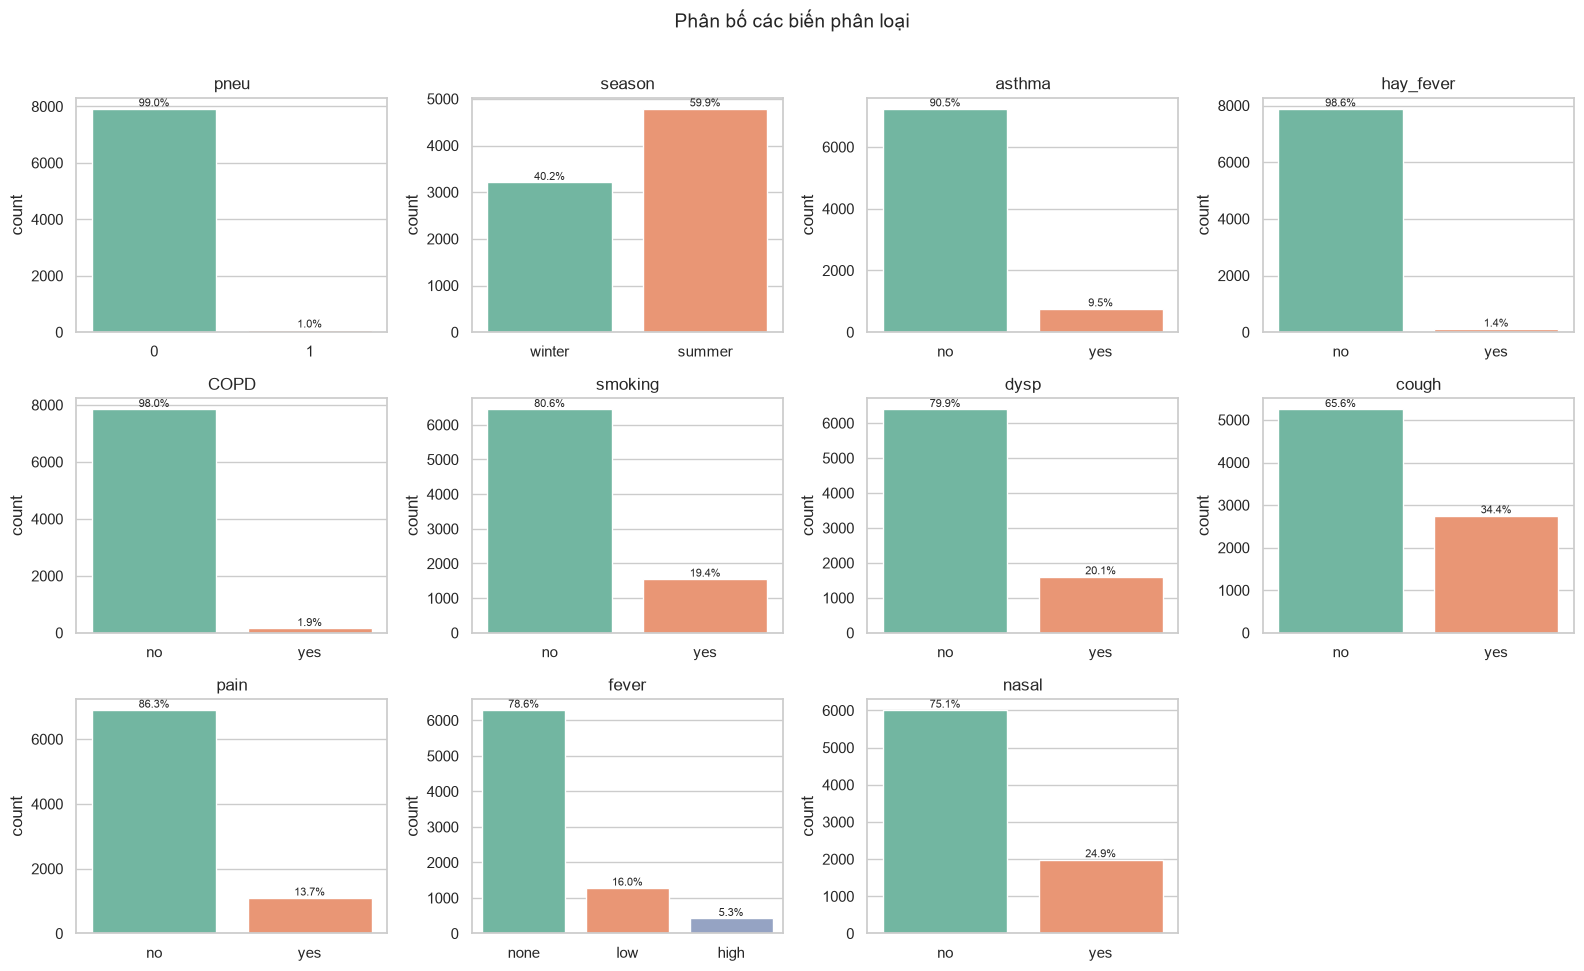

In [33]:
# Biểu đồ đếm cho các biến phân loại
n = len(cat_cols); ncols = 4; nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.2 * nrows))
for ax, c in zip(axes.ravel(), cat_cols):
    order = ["none", "low", "high"] if c == "fever" else None
    sns.countplot(data=train_df, x=c, order=order, ax=ax, palette="Set2")
    ax.set_title(c); ax.set_xlabel("")
    for p in ax.patches:
        ax.annotate(f"{p.get_height()/len(train_df):.1%}", (p.get_x()+p.get_width()/2, p.get_height()),
                    ha="center", va="bottom", fontsize=8)
for ax in axes.ravel()[n:]: ax.axis("off")
plt.suptitle("Phân bố các biến phân loại", y=1.01, fontsize=14)
plt.tight_layout(); plt.show()

CHỈ XÉT TRONG TẬP TRAIN\
**Vấn đề**\
pnue: Chỉ có 82 ca dương tính (1.03%) trên tổng số 8000 hồ sơ (tỷ lệ 1:99).\
=> `pneu` rất mất cân bằng: cần stratified split, class_weight / resampling và dùng PR-AUC, F1, recall thay vì dùng Accuracy làm chuẩn đánh giá, mô hình dự đoán "không bệnh" toàn bộ cũng đạt độ chính xác 99% nhưng hoàn toàn vô giá trị trong y tế. 

**Nhóm 1: Mất cân bằng nặng (Tỷ lệ nhóm thiểu số dưới 5%)**\
hay_fever (Sốt cỏ khô): Chỉ có 1.4% là yes, còn 98.6% là no.\
COPD (Phổi tắc nghẽn mạn tính): Chỉ có 1.9% là yes, còn 98% là no.\
fever (Sốt - biến 3 mức): Mức high (Sốt cao) chỉ chiếm 5.3%, trong khi mức none chiếm tới 78.6%.\

**Nhóm 2: Mất cân bằng trung bình (Tỷ lệ nhóm thiểu số từ 5% đến 15%)**\
asthma (Hen suyễn): Chỉ có 9.5% là yes.\
pain (Đau): Chỉ có 13.7% là yes.\

**Nhóm 3: Từ 19% - 40% cho nhóm thiểu số**\
season\
smoking\
dysp\
cough\
nasal


## 3. TƯƠNG QUAN

In [ ]:
#Kiểm định thống kê: Chi-square + Cramér's V (+ Fisher OR cho biến nhị phân) cho từng cặp biến phân loại vs nhãn
def cramers_v(ct):
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum(); r, k = ct.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

res = []
for t in TARGETS:
    for c in EXTERNAL + HISTORY + SYMPTOMS:
        ct = pd.crosstab(train_df[c], train_df[t])
        chi2, p, dof, exp = stats.chi2_contingency(ct)
        row = {"target": t, "đặc trưng": c, "chi2": round(chi2, 2), "p-value chi2": p,
               "Cramér's V": round(cramers_v(ct), 3),
               "ô kỳ vọng <5": bool((exp < 5).any())}
        if ct.shape == (2, 2):
            row["Odds ratio"], row["Fisher p"] = stats.fisher_exact(ct)[0], stats.fisher_exact(ct)[1]
        res.append(row)
res = pd.DataFrame(res)
res["có ý nghĩa (p chi2<0.05)"] = res["p-value chi2"] < 0.05
res["p-value chi2"] = res["p-value chi2"].map(lambda x: f"{x:.2e}")
for t in TARGETS:
    print(f"\n===== {t} =====")
    display(res[res.target == t].drop(columns="target").sort_values("Cramér's V", ascending=False).reset_index(drop=True))
print("Ghi chú: với feature có ô kỳ vọng <5 = True -> ưu tiên đọc Fisher p thay vì Cramer's V.")


===== pneu =====


,đặc trưng,chi2,p-value chi2,Cramér's V,ô kỳ vọng <5,Odds ratio,Fisher p,có ý nghĩa (p chi2<0.05)
0,fever,995.03,8.55e-217,0.353,True,NaN,NaN,True
1,cough,117.01,2.86e-27,0.122,False,20.976306,1.986967e-27,True
2,dysp,48.02,4.22e-12,0.079,False,4.259004,2.873406e-10,True
3,pain,46.89,7.52e-12,0.078,False,4.328905,2.317320e-09,True
4,season,15.84,6.89e-05,0.046,False,2.475809,5.972382e-05,True
5,smoking,3.40,6.52e-02,0.022,False,1.626288,6.650019e-02,False
6,COPD,0.52,4.70e-01,0.013,True,1.927277,2.147802e-01,False
7,hay_fever,0.39,5.31e-01,0.012,True,0.000000,6.330575e-01,False
8,asthma,0.41,5.20e-01,0.009,False,1.325455,4.457161e-01,False
9,nasal,0.30,5.86e-01,0.008,False,1.180998,5.207918e-01,False


Ghi chú: với feature có ô kỳ vọng <5 = True -> ưu tiên đọc Fisher p / Odds ratio thay vì Cramer's V.


**Các cột có Ô kỳ vọng < 5 = True và Fisher p > 0.5**
- hay_fever: 0.63 => không có ý nghĩa thống kê với pnue

**Các cột có Ô kỳ vọng < 5 = False và p-value chi2 > 0.5**
- asthma: 0.52
- nasal: 0.58
- smoking: 0.65

=> Nếu dựa vào thống kê, nên bỏ các cột trên, tuy nhiên có thể thử 2 trường hợp bỏ và không bỏ xem có ảnh hướng tới kết quả không.

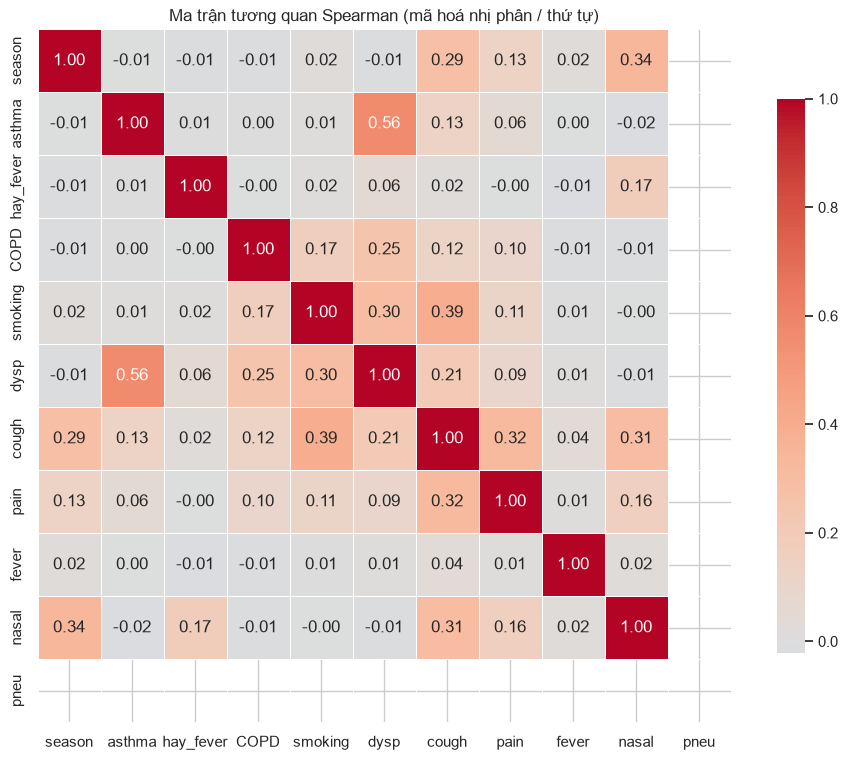

Top cặp tương quan mạnh nhất (|rho|):


,biến 1,biến 2,rho
0,asthma,dysp,0.564577
1,smoking,cough,0.393366
2,season,nasal,0.341546
3,cough,pain,0.317943
4,cough,nasal,0.313056
5,smoking,dysp,0.304840
6,season,cough,0.287758
7,COPD,dysp,0.254101
8,dysp,cough,0.210672
9,hay_fever,nasal,0.174918


In [ ]:
# Tương quan Spearman giữa các feature
# Mã hoá: yes/no -> 1/0 ; season: winter=1 ; fever: none/low/high -> 0/1/2 (thứ tự)
enc = pd.DataFrame(index=train_df.index)
for c in EXTERNAL + HISTORY + SYMPTOMS + TARGETS:
    if c == "fever":    enc[c] = train_df[c].map({"none": 0, "low": 1, "high": 2})
    elif c == "season": enc[c] = (train_df[c] == "winter").astype(int)
    else:               enc[c] = (train_df[c] == "yes").astype(int)

corr = enc.corr(method="spearman")
plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=.5, cbar_kws={"shrink": .8})
plt.title("Ma trận tương quan Spearman (mã hoá nhị phân / thứ tự)"); plt.show()

print("Top cặp tương quan mạnh nhất (|rho|):")
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().rename("rho").reset_index()
pairs.columns = ["biến 1", "biến 2", "rho"]
pairs.reindex(pairs.rho.abs().sort_values(ascending=False).index).head(12).reset_index(drop=True)

=> Mức độ tương quan giữa các biến khá thấp, cao nhất cũng chỉ 0.56 nên không phải bỏ cột nào

## 4. TEXT VÀ ADVANCED TEXT

In [ ]:
for c in TEXT_COLS:
    df[f"{c}_chars"] = df[c].str.len()
    df[f"{c}_words"] = df[c].str.split().str.len()
    df[f"{c}_lines"] = df[c].str.count("\n") + 1

print(df[[f"{c}_{m}" for c in TEXT_COLS for m in ["chars", "words"]]].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for c, col in zip(TEXT_COLS, ["#4C9BE8", "#E76F51"]):
    sns.histplot(df[f"{c}_words"], bins=40, kde=True, ax=axes[0], label=c, color=col, alpha=.5)
axes[0].set_title("Phân bố số từ"); axes[0].legend()
sns.boxplot(data=df[[f"{c}_words" for c in TEXT_COLS]].rename(columns=lambda x: x.replace("_words", "")), ax=axes[1], palette=["#4C9BE8", "#E76F51"])
axes[1].set_title("Số từ: text vs advanced_text"); plt.tight_layout(); plt.show()
print("Tỉ lệ độ dài advanced_text / text (trung vị):", round((df.advanced_text_words / df.text_words).median(), 2))